In [6]:
import pdb
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.pylab as pylab
import cartopy
import cartopy.crs as ccrs
import pickle as pkl
import glob
from metpy import calc
from metpy.units import units
import matplotlib.patches as patches
from scipy import stats
from endgame import hist2d

from matplotlib.lines import Line2D

from shared.paths import load_paths
paths = load_paths()

pylab.rcParams['figure.figsize'] = (50., 50.)
%matplotlib inline

In [5]:
cd ..

/home/users/cornkle/pythonWorkspace/proj_CEH


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# VPD helper functions
# ------------------------------------------------------------

def calc_vpd_from_t_q(t, q, p_hpa=1000.):
    """
    Calculate vapour pressure deficit from temperature and specific humidity.

    t     : temperature, usually K. If values look like Celsius, code handles it.
    q     : specific humidity, usually kg/kg. If values look like g/kg, code converts.
    p_hpa : pressure in hPa. Use 1000 hPa as near-surface approximation unless you have psfc.

    returns VPD in hPa.
    """

    t = np.asarray(t, dtype=float)
    q = np.asarray(q, dtype=float)

    # If q looks like g/kg, convert to kg/kg
    q = np.where(q > 0.1, q / 1000., q)

    # If T looks like Celsius, convert to Kelvin
    t_k = np.where(t < 150, t + 273.15, t)
    t_c = t_k - 273.15

    # saturation vapour pressure, hPa
    es = 6.112 * np.exp((17.67 * t_c) / (t_c + 243.5))

    # actual vapour pressure from specific humidity, hPa
    eps = 0.622
    e = (q * p_hpa) / (eps + (1 - eps) * q)

    vpd = es - e
    return vpd


def add_vpd_to_abs_and_anom(abs_df, anom_df, suffix='1deg', p_hpa=1000.):
    """
    Adds VPD to both:
    - abs_df: storm-day absolute VPD
    - anom_df: storm-day VPD anomaly relative to that period's own climate

    Uses:
    storm climate T = storm absolute T - storm T anomaly
    storm climate q = storm absolute q - storm q anomaly
    """

    tvar = f't_srfc_{suffix}'
    qvar = f'q_srfc_{suffix}'
    outvar = f'vpd_srfc_{suffix}'

    # storm-day absolute VPD
    vpd_abs = calc_vpd_from_t_q(abs_df[tvar], abs_df[qvar], p_hpa=p_hpa)

    # reconstruct that period's local/day climatology for T and q
    t_clim = abs_df[tvar] - anom_df[tvar]
    q_clim = abs_df[qvar] - anom_df[qvar]

    # climatological VPD
    vpd_clim = calc_vpd_from_t_q(t_clim, q_clim, p_hpa=p_hpa)

    # add to dataframes
    abs_df[outvar] = vpd_abs
    anom_df[outvar] = vpd_abs - vpd_clim

    return abs_df, anom_df

In [8]:
import numpy as np
import matplotlib.pyplot as plt

def calc_ef(lh, sh):
    """
    Evaporative fraction:
        EF = LH / (LH + SH)

    Assumes LH and SH are in the same units, e.g. W m-2.
    """
    lh = np.asarray(lh, dtype=float)
    sh = np.asarray(sh, dtype=float)

    denom = lh + sh
    ef = np.where(np.isclose(denom, 0) | np.isnan(denom), np.nan, lh / denom)
    return ef


def add_ef_to_abs_and_anom(abs_df, anom_df, suffix='1deg'):
    """
    Adds:
    - ef_1deg to abs_df  = EF from storm-day absolute LH/SH
    - ef_1deg to anom_df = EF_abs - EF_clim

    Do this separately for hist and fut.
    """

    lhvar = f'lh_{suffix}'
    shvar = f'sh_{suffix}'
    outvar = f'ef_{suffix}'

    # storm-day absolute EF
    ef_abs = calc_ef(abs_df[lhvar], abs_df[shvar])

    # reconstruct each period's climatological LH/SH
    lh_clim = abs_df[lhvar] - anom_df[lhvar]
    sh_clim = abs_df[shvar] - anom_df[shvar]

    # climatological EF
    ef_clim = calc_ef(lh_clim, sh_clim)

    # add derived absolute and derived anomaly
    abs_df[outvar] = ef_abs*100
    anom_df[outvar] = (ef_abs - ef_clim)*100

    return abs_df, anom_df

In [9]:
import numpy as np

def calc_thetae_from_t_q(t, q, p_hpa=925.):
    """
    Calculate equivalent potential temperature from temperature and specific humidity.

    t     : temperature, K or degC
    q     : specific humidity, kg/kg or g/kg
    p_hpa : pressure in hPa

    returns theta-e in K
    """

    t = np.asarray(t, dtype=float)
    q = np.asarray(q, dtype=float)

    # q: g/kg -> kg/kg if needed
    q = np.where(q > 0.1, q / 1000., q)

    # T: Celsius -> Kelvin if needed
    t_k = np.where(t < 150, t + 273.15, t)

    # avoid impossible q values
    q = np.where((q <= 0) | (q >= 1), np.nan, q)

    # mixing ratio, kg/kg
    r = q / (1. - q)

    # vapour pressure, hPa
    eps = 0.622
    e = (q * p_hpa) / (eps + (1. - eps) * q)
    e = np.where(e <= 0, np.nan, e)

    # dewpoint from vapour pressure, K
    ln_ratio = np.log(e / 6.112)
    td_c = (243.5 * ln_ratio) / (17.67 - ln_ratio)
    td_k = td_c + 273.15

    # LCL temperature, K; Bolton-style approximation
    tlcl = 1. / (1. / (td_k - 56.) + np.log(t_k / td_k) / 800.) + 56.

    # potential temperature
    rd_cp = 0.2854
    theta = t_k * (1000. / p_hpa) ** rd_cp

    # equivalent potential temperature
    thetae = theta * np.exp((3376. / tlcl - 2.54) * r * (1. + 0.81 * r))

    return thetae

In [10]:
def add_thetae_to_abs_and_anom(abs_df, anom_df, suffix='1deg', p_hpa=925.):
    """
    Adds theta-e to storm-day absolute and anomaly dataframes.

    abs_df  : lhist or lfut
    anom_df : lahist or lafut

    Adds:
        thetae_calc_1deg to abs_df
        thetae_calc_1deg to anom_df

    thetae anomaly is calculated as:
        thetae_abs - thetae_clim
    """

    tvar = f't_srfc_{suffix}'
    qvar = f'q_srfc_{suffix}'
    outvar = f'thetae_{suffix}'

    thetae_abs = calc_thetae_from_t_q(abs_df[tvar], abs_df[qvar], p_hpa=p_hpa)

    t_clim = abs_df[tvar] - anom_df[tvar]
    q_clim = abs_df[qvar] - anom_df[qvar]

    thetae_clim = calc_thetae_from_t_q(t_clim, q_clim, p_hpa=p_hpa)

    abs_df[outvar] = thetae_abs
    anom_df[outvar] = thetae_abs - thetae_clim

    return abs_df, anom_df

In [11]:
import numpy as np

def saturation_vapour_pressure_hpa(t_k):
    """
    Saturation vapour pressure over liquid water, hPa.
    Input T in K.
    """
    t_c = t_k - 273.15
    return 6.112 * np.exp((17.67 * t_c) / (t_c + 243.5))


def calc_thetae_from_t_q(t, q, p_hpa=925.):
    """
    Equivalent potential temperature from T and specific humidity.

    t     : K or degC
    q     : kg/kg or g/kg
    p_hpa : hPa

    returns theta-e in K
    """

    t = np.asarray(t, dtype=float)
    q = np.asarray(q, dtype=float)

    q = np.where(q > 0.1, q / 1000., q)       # g/kg -> kg/kg if needed
    t_k = np.where(t < 150, t + 273.15, t)   # degC -> K if needed

    q = np.where((q <= 0) | (q >= 1), np.nan, q)

    r = q / (1. - q)

    eps = 0.622
    e = (q * p_hpa) / (eps + (1. - eps) * q)
    e = np.where(e <= 0, np.nan, e)

    ln_ratio = np.log(e / 6.112)
    td_c = (243.5 * ln_ratio) / (17.67 - ln_ratio)
    td_k = td_c + 273.15

    tlcl = 1. / (1. / (td_k - 56.) + np.log(t_k / td_k) / 800.) + 56.

    theta = t_k * (1000. / p_hpa) ** 0.2854
    thetae = theta * np.exp((3376. / tlcl - 2.54) * r * (1. + 0.81 * r))

    return thetae


def calc_thetaes_from_t(t, p_hpa=650.):
    """
    Saturated equivalent potential temperature from T and pressure.

    t     : K or degC
    p_hpa : hPa

    returns saturated theta-e in K
    """

    t = np.asarray(t, dtype=float)
    t_k = np.where(t < 150, t + 273.15, t)

    eps = 0.622

    es = saturation_vapour_pressure_hpa(t_k)
    es = np.where(es >= 0.99 * p_hpa, np.nan, es)

    rs = eps * es / (p_hpa - es)

    # saturated parcel: dewpoint = temperature, LCL approximately T
    tlcl = t_k

    theta = t_k * (1000. / p_hpa) ** 0.2854
    thetaes = theta * np.exp((3376. / tlcl - 2.54) * rs * (1. + 0.81 * rs))

    return thetaes

In [12]:
def add_cape_proxy_to_abs_and_anom(abs_df, anom_df, suffix='1deg',
                                   p_srfc_hpa=925., p_mid_hpa=650.):
    """
    Adds table-based two-level CAPE proxy:

        cape_proxy_calc = thetae_srfc - thetaes_mid

    to both absolute and anomaly dataframes.

    The anomaly is calculated as:

        cape_proxy_abs - cape_proxy_clim

    not from anomaly T/q directly.
    """

    t_s_var = f't_srfc_{suffix}'
    q_s_var = f'q_srfc_{suffix}'
    t_m_var = f't_mid_{suffix}'

    thetae_var  = f'thetae_calc_{suffix}'
    thetaes_var = f'thetaes_mid_calc_{suffix}'
    cape_var    = f'cape_proxy_calc_{suffix}'

    # storm-day absolute values
    thetae_s_abs = calc_thetae_from_t_q(abs_df[t_s_var], abs_df[q_s_var],
                                        p_hpa=p_srfc_hpa)

    thetaes_m_abs = calc_thetaes_from_t(abs_df[t_m_var],
                                        p_hpa=p_mid_hpa)

    cape_abs = thetae_s_abs - thetaes_m_abs

    # reconstruct period climatology
    t_s_clim = abs_df[t_s_var] - anom_df[t_s_var]
    q_s_clim = abs_df[q_s_var] - anom_df[q_s_var]
    t_m_clim = abs_df[t_m_var] - anom_df[t_m_var]

    thetae_s_clim = calc_thetae_from_t_q(t_s_clim, q_s_clim,
                                         p_hpa=p_srfc_hpa)

    thetaes_m_clim = calc_thetaes_from_t(t_m_clim,
                                         p_hpa=p_mid_hpa)

    cape_clim = thetae_s_clim - thetaes_m_clim

    # add to dataframes
    abs_df[thetae_var] = thetae_s_abs
    abs_df[thetaes_var] = thetaes_m_abs
    abs_df[cape_var] = cape_abs

    anom_df[thetae_var] = thetae_s_abs - thetae_s_clim
    anom_df[thetaes_var] = thetaes_m_abs - thetaes_m_clim
    anom_df[cape_var] = cape_abs - cape_clim

    return abs_df, anom_df

In [13]:
lhist_orig = pd.read_csv(paths.cp4_2d + '/CP4_box_JASMIN/mean3h_v2/tables/hist_mean_table_JASMIN_3hmeansVersion_rainMask_fullBox_ICAPE_SBCAPE.csv', index_col=0, low_memory=False).T
lfut_orig = pd.read_csv(paths.cp4_2d + '/CP4_box_JASMIN/mean3h_v2/tables/fut_mean_table_JASMIN_3hmeansVersion_rainMask_fullBox_ICAPE_SBCAPE.csv', index_col=0, low_memory=False).T

In [14]:
lahist_orig = pd.read_csv(paths.cp4_2d + '/CP4_box_JASMIN/mean3h_v2/tables/hist_anom_table_JASMIN_3hmeansVersion_rainMask_fullBox_ICAPE.csv', index_col=0, low_memory=False).T
lafut_orig = pd.read_csv(paths.cp4_2d + '/CP4_box_JASMIN/mean3h_v2/tables/fut_anom_table_JASMIN_3hmeansVersion_rainMask_fullBox_ICAPE.csv', index_col=0, low_memory=False).T

In [15]:
for dat in [lahist_orig, lafut_orig, lhist_orig, lfut_orig]:
    for var in dat.keys():
        try:
            dat[var] = dat[var].astype(float)
        except:
            pass

In [16]:
print(len(lahist_orig))
print(len(lhist_orig))

24572
24282


In [17]:
hist_SM_clim = np.mean(lhist_orig['SM_2deg']-lahist_orig['SM_2deg'])
fut_SM_clim = np.mean(lfut_orig['SM_2deg']-lafut_orig['SM_2deg'])
print(hist_SM_clim, fut_SM_clim)

14.351013728114538 11.584353943636033


In [18]:
lhist_orig['SM_2deg']


0         5.681790
1        19.562296
2        24.438206
3        19.117781
4        16.643828
           ...    
24277    23.191394
24278     6.251089
24279     7.915983
24280    13.596063
24281    10.298445
Name: SM_2deg, Length: 24282, dtype: float64

In [19]:
keys = ["pmax", "area", "area_1mm"]
 
common = pd.merge(lahist_orig[keys].drop_duplicates(),lhist_orig[keys].drop_duplicates(),on=keys,how="inner")
lahist_orig = lahist_orig.merge(common, on=keys, how="inner")
lhist_orig = lhist_orig.merge(common, on=keys, how="inner")
 
common = pd.merge(lafut_orig[keys].drop_duplicates(),lfut_orig[keys].drop_duplicates(),on=keys,how="inner")
lafut_orig = lafut_orig.merge(common, on=keys, how="inner")
lfut_orig = lfut_orig.merge(common, on=keys, how="inner")

In [20]:
lahist, lafut, lhist, lfut= [df.copy() for df in (lahist_orig, lafut_orig, lhist_orig, lfut_orig)]

In [21]:
len(lahist)

20014

In [22]:
len(lhist)

20014

In [23]:
len(lafut)

14506

In [24]:
np.unique(lahist['month'])

array([7., 8., 9.])

In [25]:
np.unique(lhist['hour'])

array([17., 18., 19.])

In [26]:
lhist[lhist['hour']==19]['sw_net_2deg']

13       492.090970
14       534.890861
15       632.582725
16       594.755916
17       655.172432
            ...    
19993    574.006053
19994    580.089527
19995    637.457377
19996    611.165073
19997    692.373517
Name: sw_net_2deg, Length: 6051, dtype: float64

In [27]:
lahist['area_1mm'].min()*4.4**2

19.360000000000003

In [28]:
lahist['pmax'].min()

0.4134321472886568

In [29]:
lahist['shear_fullBox'].max()

13.874670028686523

In [30]:
dtag = '2deg'

lhist, lahist = add_vpd_to_abs_and_anom(lhist, lahist, suffix=dtag, p_hpa=925.)
lfut,  lafut  = add_vpd_to_abs_and_anom(lfut,  lafut,  suffix=dtag, p_hpa=925.)

lhist, lahist = add_ef_to_abs_and_anom(lhist, lahist, suffix=dtag)
lfut,  lafut  = add_ef_to_abs_and_anom(lfut,  lafut,  suffix=dtag)

lhist, lahist = add_thetae_to_abs_and_anom(lhist, lahist, suffix=dtag, p_hpa=925.)
lfut,  lafut  = add_thetae_to_abs_and_anom(lfut,  lafut,  suffix=dtag, p_hpa=925.)

lhist, lahist = add_cape_proxy_to_abs_and_anom(lhist, lahist, suffix=dtag, p_srfc_hpa=925., p_mid_hpa=650.)
lfut, lafut = add_cape_proxy_to_abs_and_anom(lfut, lafut, suffix=dtag, p_srfc_hpa=925., p_mid_hpa=650.)

In [31]:
dtag = '1deg'

lhist, lahist = add_vpd_to_abs_and_anom(lhist, lahist, suffix=dtag, p_hpa=925.)
lfut,  lafut  = add_vpd_to_abs_and_anom(lfut,  lafut,  suffix=dtag, p_hpa=925.)

lhist, lahist = add_ef_to_abs_and_anom(lhist, lahist, suffix=dtag)
lfut,  lafut  = add_ef_to_abs_and_anom(lfut,  lafut,  suffix=dtag)

lhist, lahist = add_thetae_to_abs_and_anom(lhist, lahist, suffix=dtag, p_hpa=925.)
lfut,  lafut  = add_thetae_to_abs_and_anom(lfut,  lafut,  suffix=dtag, p_hpa=925.)

lhist, lahist = add_cape_proxy_to_abs_and_anom(lhist, lahist, suffix=dtag, p_srfc_hpa=925., p_mid_hpa=650.)
lfut, lafut = add_cape_proxy_to_abs_and_anom(lfut, lafut, suffix=dtag, p_srfc_hpa=925., p_mid_hpa=650.)

In [32]:
print(len(lhist),len(lahist))

20014 20014


In [33]:
print(list(lfut.keys()))

['tcwv_0.25deg', 'tcwv_1deg', 'tcwv_2deg', 'tcwv_fullBox', 'sh_0.25deg', 'sh_1deg', 'sh_2deg', 'sh_fullBox', 'lh_0.25deg', 'lh_1deg', 'lh_2deg', 'lh_fullBox', 't2_0.25deg', 't2_1deg', 't2_2deg', 't2_fullBox', 'q2_0.25deg', 'q2_1deg', 'q2_2deg', 'q2_fullBox', 'shear_0.25deg', 'shear_1deg', 'shear_2deg', 'shear_fullBox', 'u_mid_0.25deg', 'u_mid_1deg', 'u_mid_2deg', 'u_mid_fullBox', 'u_srfc_0.25deg', 'u_srfc_1deg', 'u_srfc_2deg', 'u_srfc_fullBox', 'v_mid_0.25deg', 'v_mid_1deg', 'v_mid_2deg', 'v_mid_fullBox', 'v_srfc_0.25deg', 'v_srfc_1deg', 'v_srfc_2deg', 'v_srfc_fullBox', 'q_mid_0.25deg', 'q_mid_1deg', 'q_mid_2deg', 'q_mid_fullBox', 't_mid_0.25deg', 't_mid_1deg', 't_mid_2deg', 't_mid_fullBox', 't_srfc_0.25deg', 't_srfc_1deg', 't_srfc_2deg', 't_srfc_fullBox', 'q_srfc_0.25deg', 'q_srfc_1deg', 'q_srfc_2deg', 'q_srfc_fullBox', 'geoH_srfc_0.25deg', 'geoH_srfc_1deg', 'geoH_srfc_2deg', 'geoH_srfc_fullBox', 'lsRain_noon_0.25deg', 'lsRain_noon_1deg', 'lsRain_noon_2deg', 'lsRain_noon_fullBox', 'lw

In [34]:
import math

In [35]:
print(math.sqrt(np.percentile(lhist['area']*4.4**2,25)/ math.pi) *2)
print(math.sqrt(np.percentile(lhist['area']*4.4**2,75)/ math.pi) *2)

94.72365069680583
159.9581647004726


In [36]:
print(math.sqrt(np.percentile(lfut['area']*4.4**2,25)/ math.pi) *2)
print(math.sqrt(np.percentile(lfut['area']*4.4**2,75)/ math.pi) *2)

96.4003056527801
174.40756377294474


In [37]:
lahist = lahist[(lhist['pmax']>=1) ]
lhist = lhist[(lhist['pmax']>=1) ]

lafut = lafut[(lfut['pmax']>=1) ]
lfut = lfut[(lfut['pmax']>=1) ]

In [38]:
# lahist = lahist[(lhist['lat']<=16) ]
# lhist = lhist[(lhist['lat']<=16) ]

# lafut = lafut[(lfut['lat']<=16) ]
# lfut = lfut[(lfut['lat']<=16) ]

In [39]:
print(len(lhist),len(lahist))

19894 19894


In [40]:
print(len(lfut),len(lafut))

14455 14455


In [41]:
print(np.min(lhist['lat']))
print(np.max(lhist['lat']))
print(np.min(lfut['lat']))
print(np.max(lfut['lat']))

print(np.min(lhist['lon']))
print(np.max(lhist['lon']))
print(np.min(lfut['lon']))
print(np.max(lfut['lon']))

8.016003
22.474499
8.016003
22.677006
-15.67099
22.682495
-15.67099
22.682495


In [42]:
print('SM min max')
print('lhist min', lhist['SM_2deg'].min())
print('lhist max',lhist['SM_2deg'].max())
print('lfut min',lfut['SM_2deg'].min())
print('lfut max',lfut['SM_2deg'].max())

print('SM anomaly min max')
print('lahist min', lahist['SM_2deg'].min())
print('lahist max',lahist['SM_2deg'].max())
print('lafut min',lafut['SM_2deg'].min())
print('lafut max',lafut['SM_2deg'].max())

print('SM percentiles 25, 75')

print('lhist 25', np.nanpercentile(lhist['SM_2deg'], 25))
print('lhist 75',np.nanpercentile(lhist['SM_2deg'], 75))
print('lfut 25',np.nanpercentile(lfut['SM_2deg'], 25))
print('lfut 75',np.nanpercentile(lfut['SM_2deg'], 75))

print('SM anomaly percentiles 25, 75')
print('lahist 25', np.nanpercentile(lahist['SM_2deg'], 25))
print('lahist 75',np.nanpercentile(lahist['SM_2deg'], 75))
print('lafut 25',np.nanpercentile(lafut['SM_2deg'], 25))
print('lafut 75',np.nanpercentile(lafut['SM_2deg'], 75))

SM min max
lhist min 0.07336569700951283
lhist max 30.619245523930694
lfut min 0.05162553221230147
lfut max 29.23878249003717
SM anomaly min max
lahist min -12.153117093620118
lahist max 15.369679937162337
lafut min -13.34209658434301
lafut max 18.839360160063823
SM percentiles 25, 75
lhist 25 8.776817591426278
lhist 75 18.549645053220313
lfut 25 4.771743707910767
lfut 75 13.907433413121753
SM anomaly percentiles 25, 75
lahist 25 -3.069373148619687
lahist 75 1.2701124875938048
lafut 25 -4.469566451840368
lafut 75 0.1544570948576085


In [43]:
sm_hist = lhist['SM_2deg'].to_numpy()
sm_fut  = lfut['SM_2deg'].to_numpy()

sm_hist = sm_hist[np.isfinite(sm_hist)]
sm_fut  = sm_fut[np.isfinite(sm_fut)]

hist_mean, hist_median = np.mean(sm_hist), np.median(sm_hist)
fut_mean, fut_median   = np.mean(sm_fut), np.median(sm_fut)

print(f"Historical SM: mean = {hist_mean:.4f}, median = {hist_median:.4f}")
print(f"Future SM:     mean = {fut_mean:.4f}, median = {fut_median:.4f}\n")

comparisons = [
    ("Future cases above historical mean",   np.sum(sm_fut > hist_mean),   len(sm_fut)),
    ("Future cases above historical median", np.sum(sm_fut > hist_median), len(sm_fut)),
    ("Historical cases below future mean",   np.sum(sm_hist < fut_mean),   len(sm_hist)),
    ("Historical cases below future median", np.sum(sm_hist < fut_median), len(sm_hist)),
]

for label, n, total in comparisons:
    print(f"{label}: {n:,} / {total:,} ({100*n/total:.1f}%)")

Historical SM: mean = 13.6079, median = 13.3985
Future SM:     mean = 9.6988, median = 8.9016

Future cases above historical mean: 3,670 / 13,989 (26.2%)
Future cases above historical median: 3,797 / 13,989 (27.1%)
Historical cases below future mean: 5,752 / 19,334 (29.8%)
Historical cases below future median: 4,964 / 19,334 (25.7%)


In [1]:
def bootstrap_shift_difference(hdry, hwet, fdry, fwet,
                               n_boot=5000, seed=42):

    hdry = np.asarray(hdry, float)
    hwet = np.asarray(hwet, float)
    fdry = np.asarray(fdry, float)
    fwet = np.asarray(fwet, float)

    hdry = hdry[np.isfinite(hdry)]
    hwet = hwet[np.isfinite(hwet)]
    fdry = fdry[np.isfinite(fdry)]
    fwet = fwet[np.isfinite(fwet)]

    # observed difference in median climate shifts
    observed = (
        (np.median(fdry) - np.median(hdry))
        -
        (np.median(fwet) - np.median(hwet))
    )

    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)

    for i in range(n_boot):

        hdb = rng.choice(hdry, len(hdry), replace=True)
        hwb = rng.choice(hwet, len(hwet), replace=True)
        fdb = rng.choice(fdry, len(fdry), replace=True)
        fwb = rng.choice(fwet, len(fwet), replace=True)

        boot[i] = (
            (np.median(fdb) - np.median(hdb))
            -
            (np.median(fwb) - np.median(hwb))
        )

    lo, hi = np.percentile(boot, [2.5, 97.5])

    significant = (lo > 0) or (hi < 0)

    return {
        'observed': observed,
        'ci_low': lo,
        'ci_high': hi,
        'significant': significant
    }

Climate-specific SM thresholds: -3.069373148619687 1.2701124875938048 -4.469566451840368 0.1544570948576085
Sample sizes (H-WET, H-DRY, F-WET, F-DRY): 4748 4877 3322 3515
SM anomaly: HIST thresholds -3.10, 1.24; DRY 25.0% -> 40.2%; WET 25.0% -> 16.7%
EF anomaly: HIST thresholds -6.69, 4.08; DRY 25.0% -> 45.9%; WET 25.0% -> 22.3%


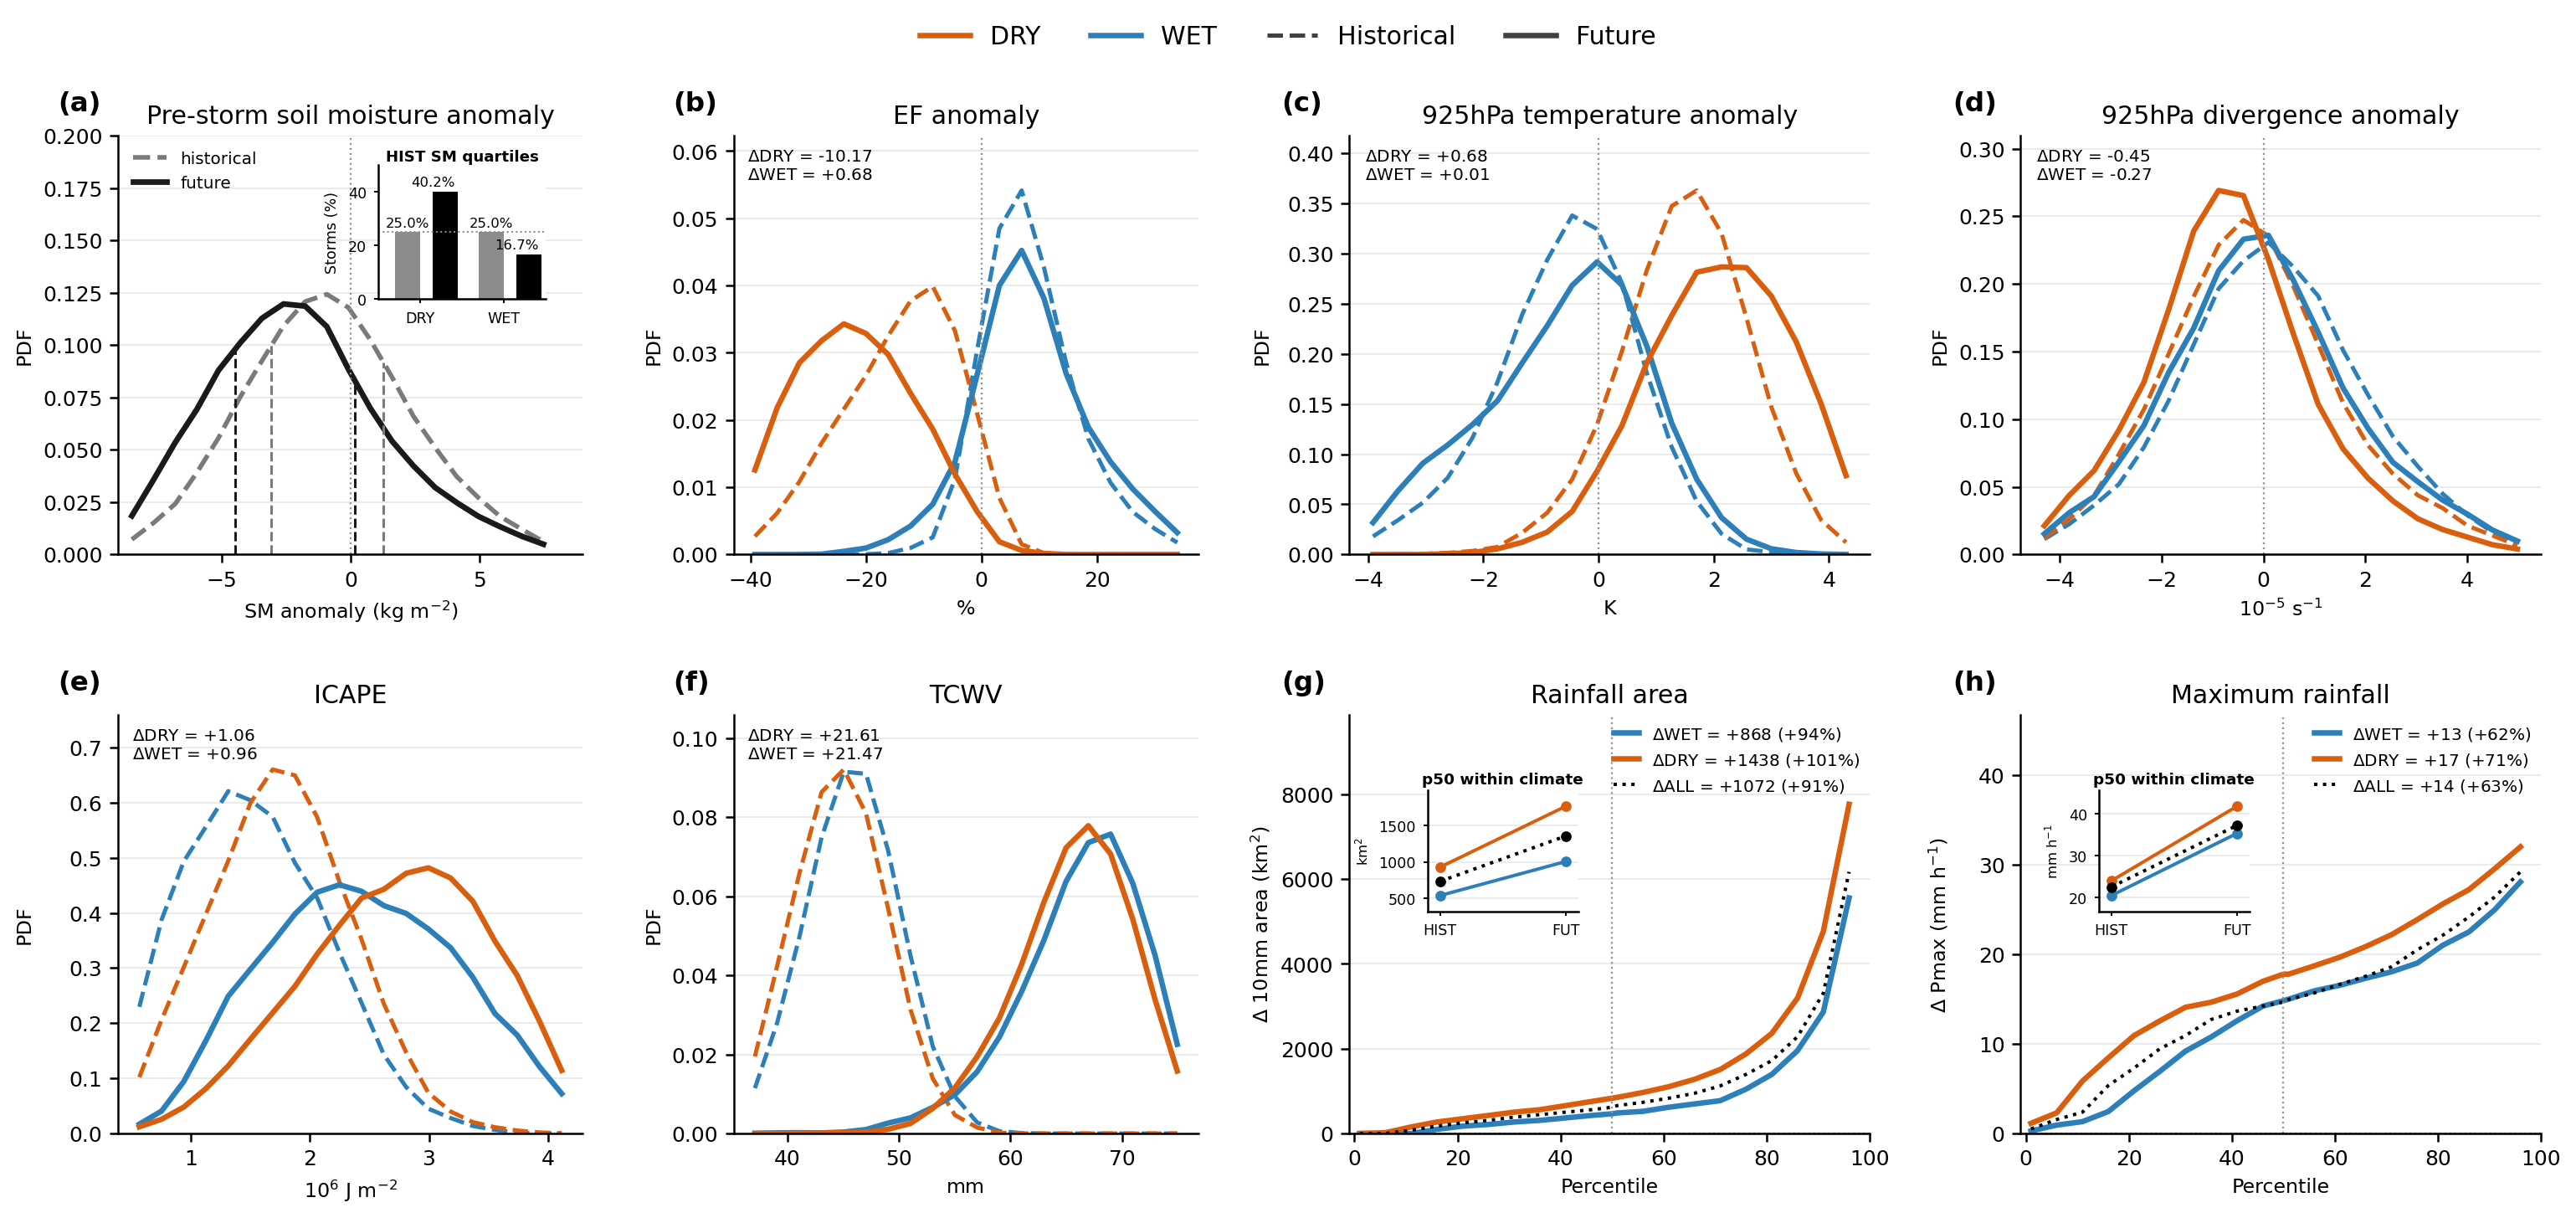

In [45]:
dtag = '1deg'
v_thresh_up, v_thresh_down = 50, -50
area_thresh, grid_km = 500000, 4.4
summary_percentile = 50

output_file = '/home/users/cornkle/pythonWorkspace/proj_CEH/JASMIN/CP4_sm_paper/figures/fig2_PDFs_'+dtag+'.jpg'

# (variable, title, x label, source, scale, zero line, decimals)
PDF_PANELS = {
    'ef':    ('ef_'+dtag,        'EF anomaly', '%', 'anom', 1,    True,  2),
    't2':    ('t_srfc_'+dtag,    '925hPa temperature anomaly',      'K', 'anom', 1,    True,  2),
    'div':   ('div_'+dtag,       '925hPa divergence anomaly',   r'$10^{-5}$ s$^{-1}$', 'anom', 1e5, True, 2),
    'icape': ('ICAPEfull_'+dtag, 'ICAPE', r'$10^{6}$ J m$^{-2}$', 'abs', 1e-6, False, 2),
    'tcwv':  ('tcwv_'+dtag,      'TCWV',    'mm', 'abs', 1,    False, 2),
}
AREA_VAR, PMAX_VAR = 'area_10mm', 'pmax'
AREA_PP = np.unique(np.r_[np.arange(1, 99, 5), summary_percentile])
PMAX_PP = np.unique(np.r_[np.arange(1, 99, 5), summary_percentile])

# Plot appearance
wet_col, dry_col, all_col = '#2C7FB8', '#D95F0E', '0.48'
hist_col, fut_col = '0.48', '0.10'
pdf_opts = dict(nbins=20, qrange=(1, 99), smooth=3)


# =============================================================================
# SM SPLIT AND SAMPLING FILTERS
# =============================================================================
# Climate-specific SM-anomaly thresholds from the full tables, BEFORE filtering.
histp25, histp75 = np.nanpercentile(lahist['SM_2deg'], [25, 75])
futp25, futp75 = np.nanpercentile(lafut['SM_2deg'], [25, 75])

# Additional sampling filters, applied after defining the thresholds.
hist_north = (lhist['v_mid_fullBox'] < v_thresh_up) & (lhist['v_mid_fullBox'] > v_thresh_down)
fut_north = (lfut['v_mid_fullBox'] < v_thresh_up) & (lfut['v_mid_fullBox'] > v_thresh_down)
hist_area = lhist['area'] * grid_km**2 < area_thresh
fut_area = lfut['area'] * grid_km**2 < area_thresh
hist_split_sample, fut_split_sample = hist_north & hist_area, fut_north & fut_area

histposlow = (lahist['SM_2deg'] > histp75) & hist_split_sample   # WET
histposhigh = (lahist['SM_2deg'] < histp25) & hist_split_sample  # DRY
futposlow = (lafut['SM_2deg'] > futp75) & fut_split_sample       # WET
futposhigh = (lafut['SM_2deg'] < futp25) & fut_split_sample      # DRY

# ALL uses the area filter only, matching the other code.
histall, futall = hist_area, fut_area

print('Climate-specific SM thresholds:', histp25, histp75, futp25, futp75)
print('Sample sizes (H-WET, H-DRY, F-WET, F-DRY):',
      histposlow.sum(), histposhigh.sum(), futposlow.sum(), futposhigh.sum())


# =============================================================================
# HELPERS
# =============================================================================
def _clean(x, scale=1):
    x = np.asarray(x, dtype=float) * scale
    return x[np.isfinite(x)]


def _smooth(y, n=3):
    return y if n <= 1 else np.convolve(y, np.ones(n) / n, mode='same')


def _make_bins(arrs, nbins=36, qrange=(1, 99)):
    pooled = np.concatenate([a for a in arrs if len(a) > 0])
    lo, hi = np.nanpercentile(pooled, qrange)
    return np.linspace(lo, hi, nbins + 1)


def _pdf(vals, bins, smooth=3):
    hist, edges = np.histogram(vals, bins=bins, density=True)
    return 0.5 * (edges[1:] + edges[:-1]), _smooth(hist, smooth)


def style_ax(ax, zero_y=False):
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(direction='out', labelsize=10, width=1, length=4)
    ax.grid(axis='y', color='0.91', lw=0.7, zorder=0)
    if zero_y:
        ax.axhline(0, color='0.55', ls=':', lw=0.9, zorder=0)


def panel_label(ax, label):
    ax.text(-0.13, 1.045, f'({label})', transform=ax.transAxes,
            ha='left', va='bottom', fontsize=13, fontweight='semibold',
            color='black', clip_on=False)


def fixed_frequency(hist, fut, var, hmask, fmask):
    """Shares outside fixed historical quartile thresholds."""
    h, f = _clean(hist.loc[hmask, var]), _clean(fut.loc[fmask, var])
    q25, q75 = np.nanpercentile(h, [25, 75])
    out = {'q25': q25, 'q75': q75,
           'hist_dry': 100*np.mean(h < q25), 'fut_dry': 100*np.mean(f < q25),
           'hist_wet': 100*np.mean(h > q75), 'fut_wet': 100*np.mean(f > q75)}
    return out


# Basic frequency statistics for text/reporting.
sm_frequency = fixed_frequency(lahist, lafut, 'SM_2deg',
                               hist_split_sample, fut_split_sample)
ef_frequency = fixed_frequency(lahist, lafut, 'ef_2deg',
                               hist_split_sample, fut_split_sample)
for name, stat in [('SM anomaly', sm_frequency), ('EF anomaly', ef_frequency)]:
    print(f"{name}: HIST thresholds {stat['q25']:.2f}, {stat['q75']:.2f}; "
          f"DRY {stat['hist_dry']:.1f}% -> {stat['fut_dry']:.1f}%; "
          f"WET {stat['hist_wet']:.1f}% -> {stat['fut_wet']:.1f}%")


# =============================================================================
# PDF PANELS
# =============================================================================
def plot_sm_pdf(ax):
    """Full SM anomaly PDF plus frequency under fixed historical thresholds."""
    hs = _clean(lahist.loc[hist_split_sample, 'SM_2deg'])
    fs = _clean(lafut.loc[fut_split_sample, 'SM_2deg'])
    bins = _make_bins([hs, fs], **{k: pdf_opts[k] for k in ('nbins', 'qrange')})
    
    hx, hy = _pdf(hs, bins, pdf_opts['smooth'])
    fx, fy = _pdf(fs, bins, pdf_opts['smooth'])
    
    ax.plot(hx, hy, color=hist_col, ls='--', lw=2.2, label='historical')
    ax.plot(fx, fy, color=fut_col,  ls='-',  lw=2.7, label='future')
    
    for q in [histp25, histp75]:
        ax.vlines(q, 0, np.interp(q, hx, hy),
                  color=hist_col, ls='--', lw=1.2)
    
    for q in [futp25, futp75]:
        ax.vlines(q, 0, np.interp(q, fx, fy),
                  color=fut_col, ls='--', lw=1.2)

    
    ax.axvline(0, color='0.58', ls=':', lw=0.9)
    
    ax.set(title='Pre-storm soil moisture anomaly',
           xlabel=r'SM anomaly (kg m$^{-2}$)', ylabel='PDF')
    ax.legend(frameon=False, fontsize=8, loc='upper left')
    ax.set_ylim(0,0.2)
    ax.set_xlim(-9,9)
    
    style_ax(ax)

    # Compact inset: future share in historically DRY/WET anomaly classes.
    iax = ax.inset_axes([0.56, 0.61, 0.36, 0.32])
    vals = np.array([[sm_frequency['hist_dry'], sm_frequency['hist_wet']],
                     [sm_frequency['fut_dry'], sm_frequency['fut_wet']]])
    xx, width = np.arange(2), 0.3
    iax.bar(xx-width/2, vals[0], width, color='0.55')
    iax.bar(xx+width+0.001/2, vals[1], width, color='k')
    for off, row in zip([-width/2, width/2], vals):
        for xpos, value in zip(xx+off, row):
            iax.text(xpos, value+1, f'{value:.1f}%', ha='center', va='bottom', fontsize=6.6)
    iax.axhline(25, color='0.55', ls=':', lw=0.8)
    iax.set_xticks(xx, ['DRY', 'WET'], fontsize=7)
    iax.set_ylim(0, max(50, vals.max()*1.18))

    iax.set_xlim(-0.5, 1.5)
    
    iax.set_ylabel('Storms (%)', fontsize=7)
    iax.set_title('HIST SM quartiles', fontsize=7.3, pad=2, fontweight='bold')
    iax.tick_params(labelsize=7, length=2)
    iax.spines[['top', 'right']].set_visible(False)

    


def plot_group_pdf(ax, key):
    var, title, xlabel, source, scale, zero_line, decimals = PDF_PANELS[key]
    hdata, fdata = (lhist, lfut) if source == 'abs' else (lahist, lafut)
    hwet, hdry = _clean(hdata.loc[histposlow, var], scale), _clean(hdata.loc[histposhigh, var], scale)
    fwet, fdry = _clean(fdata.loc[futposlow, var], scale), _clean(fdata.loc[futposhigh, var], scale)
    bins = _make_bins([hwet, hdry, fwet, fdry], **{k: pdf_opts[k] for k in ('nbins', 'qrange')})

    ymax = 0

    for vals, col, ls, lw in [(hwet, wet_col, '--', 2), (hdry, dry_col, '--', 2),
                              (fwet, wet_col, '-', 2.6), (fdry, dry_col, '-', 2.6)]:
        x, y = _pdf(vals, bins, pdf_opts['smooth'])
        ax.plot(x, y, color=col, ls=ls, lw=lw)
        ymax = max(ymax, np.nanmax(y))

    ax.set_ylim(0, ymax * 1.15)

    ddry = np.nanmedian(fdry) - np.nanmedian(hdry)
    dwet = np.nanmedian(fwet) - np.nanmedian(hwet)

    sig = bootstrap_shift_difference(hdry, hwet, fdry, fwet,n_boot=5000)
    star = '*' if sig['significant'] else ''

    ax.text(0.03, 0.97,
            fr'$\Delta$DRY = {ddry:+.{decimals}f}' + '\n' +
            fr'$\Delta$WET = {dwet:+.{decimals}f}',
            transform=ax.transAxes, ha='left', va='top', fontsize=8)

    if zero_line:
        ax.axvline(0, color='0.58', ls=':', lw=0.9)


    ax.set(title=title + (' *' if sig['significant'] else ''),xlabel=xlabel,ylabel='PDF')
    style_ax(ax)


# =============================================================================
# STORM-RESPONSE PANELS AND WITHIN-CLIMATE Q99 INSETS
# =============================================================================
def _groups(hdata, fdata, var, factor):
    return {
        'WET': (_clean(hdata.loc[histposlow, var], factor), _clean(fdata.loc[futposlow, var], factor), wet_col, 2.6, '-'),
        'DRY': (_clean(hdata.loc[histposhigh, var], factor), _clean(fdata.loc[futposhigh, var], factor), dry_col, 2.6, '-'),
        'ALL': (_clean(hdata[var], factor),_clean(fdata[var], factor),'k', 1.6, ':'),
    }


def _baseline_inset(ax, groups, percentile, unit):
    """Actual quantiles; vertical DRY/WET gaps are within-climate differences."""
    iax = ax.inset_axes([0.15, 0.53, 0.29, 0.29], zorder=5)
    iax.set_facecolor('white')
    qvals = {}
    for label, (hist, fut, colour, lw, ls) in groups.items():
        qh, qf = np.nanpercentile(hist, percentile), np.nanpercentile(fut, percentile)
        qvals[label] = (qh, qf)
        iax.plot([0, 1], [qh, qf], color=colour, marker='o', ms=4.1, lw=1.6, ls=ls)
    hgap = qvals['DRY'][0]-qvals['WET'][0]
    fgap = qvals['DRY'][1]-qvals['WET'][1]
    iax.set_title(fr'p{percentile:g} within climate', fontsize=7.4, pad=3,
                  fontweight='semibold')
    #iax.text(0.5, 0.84, fr'DRY$-$WET: H {hgap:+.1f}; F {fgap:+.1f}',
    #         transform=iax.transAxes, ha='center', va='top', fontsize=6.6)
    iax.set_xticks([0, 1], ['HIST', 'FUT'])
    iax.set_ylabel(unit, fontsize=6.6)
    iax.margins(x=0.10, y=0.18)
    iax.tick_params(labelsize=7, length=2)
    iax.grid(axis='y', color='0.9', lw=0.6)
    iax.spines[['top', 'right']].set_visible(False)


def plot_change_panel(ax, var, pp, factor, unit, ylabel, title):
    # Storm properties are held in the anomaly tables in the current workflow.
    groups = _groups(lahist, lafut, var, factor)
    for label, (hist, fut, colour, lw,ls) in groups.items():
        hq, fq = np.nanpercentile(hist, pp), np.nanpercentile(fut, pp)
        change = fq-hq
        absolute, baseline = np.mean(change), np.mean(hq)
        relative = 100*absolute/baseline if baseline != 0 else np.nan
        ax.plot(pp, change, color=colour, lw=lw, ls=ls,
                label=fr'$\Delta${label} = {absolute:+.0f} ({relative:+.0f}%)')
    ax.axhline(0, color='0.55', ls=':', lw=0.9)

    
    ax.set(title=title + sigstar, xlabel='Percentile', ylabel=ylabel, xlim=(pp.min()-2, 100))
    
    ax.legend(frameon=False, fontsize=8, loc='upper right',
              handlelength=1.5, borderaxespad=0.2)

    ax.set_ylim(0,np.max(change)+np.max(change)*0.6)
    ax.axvline(50, color='0.58', ls=':', lw=0.9)
    
    _baseline_inset(ax, groups, summary_percentile, unit)
    style_ax(ax)


# =============================================================================
# BUILD FIGURE
# =============================================================================
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 12,
                     'axes.titleweight': 'normal', 'axes.labelsize': 9.5,
                     'axes.linewidth': 1.0, 'savefig.bbox': 'tight'})

fig, axs = plt.subplots(2, 4, figsize=(17.2, 8.0), dpi=180,
                        gridspec_kw={'width_ratios': [1, 1, 1.12, 1.12]})

# Top: land-effect chain
plot_sm_pdf(axs[0, 0])
plot_group_pdf(axs[0, 1], 'ef')
plot_group_pdf(axs[0, 2], 't2')
plot_group_pdf(axs[0, 3], 'div')

# Bottom: thermodynamic state and MCS response
plot_group_pdf(axs[1, 0], 'icape')
plot_group_pdf(axs[1, 1], 'tcwv')
plot_change_panel(axs[1, 2], AREA_VAR, AREA_PP, grid_km**2, r'km$^2$',
                  r'$\Delta$ 10mm area (km$^2$)', 'Rainfall area')
plot_change_panel(axs[1, 3], PMAX_VAR, PMAX_PP, 1, r'mm h$^{-1}$',
                  r'$\Delta$ Pmax (mm h$^{-1}$)', 'Maximum rainfall')

for label, ax in zip('abcdefgh', axs.flat):
    panel_label(ax, label)

# One compact key for the repeated state/line encoding.
handles = [Line2D([], [], color=dry_col, lw=2.6, label='DRY'),
           Line2D([], [], color=wet_col, lw=2.6, label='WET'),
           Line2D([], [], color='0.25', ls='--', lw=2, label='Historical'),
           Line2D([], [], color='0.25', ls='-', lw=2.6, label='Future')]
fig.legend(handles=handles, frameon=False, ncol=4, loc='upper center',
           bbox_to_anchor=(0.5, 1.015), fontsize=12)

fig.align_ylabels(axs)
plt.tight_layout(rect=(0, 0, 1, 0.96), w_pad=1.8, h_pad=2.2)

fig.savefig(output_file, dpi=300, bbox_inches='tight')
plt.show()
